<a href="https://colab.research.google.com/github/nxy2006/AIDL-Proj/blob/main/AIDL_proj.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install grad-cam

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for grad-cam: filename=grad_cam-1.5.7-py3-none-any.whl size=53345 sha256=8b643760e3c2321dc443997b451e907f9ba1e89f21b67e12a000e11126ead3e2
  Stored in directory: /root/.cache/pip/wheels/91/36/f0/c2367865493d51b13369769181beca14603d17d6539a5922e3
Successfully built grad-cam
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [grad-cam]


In [ ]:

# ==========================================
# 1. Install Kaggle API
# ==========================================
!pip install -q kaggle

import os
import getpass
from google.colab import files

# ==========================================
# 2. Authenticate with Kaggle API
# ==========================================
print("Please enter your NEW Kaggle API token:")

os.environ["KAGGLE_API_TOKEN"] = getpass.getpass(
    "Kaggle API Token: "
)

# ==========================================
# 3. Download the Oral Image Dataset
# ==========================================
!kaggle datasets download -d jhirshaikh/oral-image-dataset

# ==========================================
# 4. Unzip the Dataset
# ==========================================
!mkdir -p dataset
!unzip -q -o oral-image-dataset.zip -d dataset

# ==========================================
# 5. Verify Dataset Download
# ==========================================
print("Dataset downloaded and unzipped successfully!")

print("\nDataset contents:")

for root, dirs, filenames in os.walk("dataset"):
    for filename in filenames[:5]:
        print(os.path.join(root, filename))


Please enter your NEW Kaggle API token:
Kaggle API Token: ··········
Dataset URL: https://www.kaggle.com/datasets/jhirshaikh/oral-image-dataset
License(s): CC0-1.0
100% 429M/429M [00:05<00:00, 87.3MB/s]

Dataset downloaded and unzipped successfully!

Dataset contents:
dataset/oral dataset/tooth discoloration/164.jpg
dataset/oral dataset/tooth discoloration/44.jpg
dataset/oral dataset/tooth discoloration/Tooth_Discoloration_0_4362.jpeg
dataset/oral dataset/tooth discoloration/Tooth_Discoloration_0_2657.jpeg
dataset/oral dataset/tooth discoloration/Tooth_Discoloration_0_4070.jpeg
dataset/oral dataset/Hypodontia/(1230).jpg
dataset/oral dataset/Hypodontia/(440).JPG
dataset/oral dataset/Hypodontia/(903).jpg
dataset/oral dataset/Hypodontia/(944).jpg
dataset/oral dataset/Hypodontia/(141).JPG
dataset/oral dataset/Calculus/(1230).jpg
dataset/oral dataset/Calculus/(474).jpg
dataset/oral dataset/Calculus/(903).jpg
dataset/oral dataset/Calculus/(624).jpg
dataset/oral dataset/Calculus/(944).jpg
dat

In [ ]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split
import numpy as np
from collections import Counter
import os

# Define how we manipulate the images
data_transforms = {
    'train': transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.RandomHorizontalFlip(),
        transforms.RandomRotation(15),
        transforms.ColorJitter(brightness=0.2, contrast=0.2),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
    'val': transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
}

# --- FIX: Automatically handle Kaggle's nested folder structure ---
data_dir = './dataset'
subfolders = [f for f in os.listdir(data_dir) if os.path.isdir(os.path.join(data_dir, f))]

# If the zip extracted into a single main folder, step inside it
if len(subfolders) == 1:
    data_dir = os.path.join(data_dir, subfolders[0])

print(f"Loading data from: {data_dir}")

# Load the dataset
full_dataset = datasets.ImageFolder(data_dir, transform=data_transforms['train'])

print(f"Found {len(full_dataset.classes)} classes: {full_dataset.classes}")
# ------------------------------------------------------------------

# Split into 80% training, 20% validation
train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size
train_dataset, val_dataset = random_split(full_dataset, [train_size, val_size])

# Apply the validation transform to the validation set
val_dataset.dataset.transform = data_transforms['val']

# Create DataLoaders
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

# Calculate class weights for the 6 classes to handle imbalance
class_counts = dict(Counter(full_dataset.targets))
total_samples = sum(class_counts.values())

# Ensure weights are created correctly based on the actual number of classes found
class_weights = [total_samples / class_counts[i] for i in range(len(class_counts))]

# Set device dynamically depending on what is available
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
class_weights = torch.FloatTensor(class_weights).to(device)

print(f"Class Weights Shape: {class_weights.shape}")

Loading data from: ./dataset/oral dataset
Found 6 classes: ['Calculus', 'Hypodontia', 'Mouth ulcer', 'Normal', 'caries', 'tooth discoloration']
Class Weights Shape: torch.Size([6])


In [ ]:
import torch.nn as nn
from torchvision import models

# Set device to GPU
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

# Load pre-trained MobileNet
model = models.mobilenet_v3_small(weights=models.MobileNet_V3_Small_Weights.DEFAULT)

# Freeze the feature extraction layers so we don't destroy the pre-trained knowledge
for param in model.features.parameters():
    param.requires_grad = False

# Replace the final classification layer to match our 6 classes
num_features = model.classifier[3].in_features
model.classifier[3] = nn.Linear(num_features, 6)

model = model.to(device)

# Define Loss function (using our calculated weights) and Optimizer
criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.Adam(model.classifier.parameters(), lr=0.001)

In [ ]:
import time

epochs = 10

for epoch in range(epochs):
    print(f'Epoch {epoch+1}/{epochs}')
    print('-' * 10)

    for phase in ['train', 'val']:
        if phase == 'train':
            model.train()
            dataloader = train_loader
        else:
            model.eval()
            dataloader = val_loader

        running_loss = 0.0
        running_corrects = 0

        for inputs, labels in dataloader:
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad()

            with torch.set_grad_enabled(phase == 'train'):
                outputs = model(inputs)
                _, preds = torch.max(outputs, 1)
                loss = criterion(outputs, labels)

                if phase == 'train':
                    loss.backward()
                    optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            running_corrects += torch.sum(preds == labels.data)

        epoch_loss = running_loss / len(dataloader.dataset)
        epoch_acc = running_corrects.double() / len(dataloader.dataset)

        print(f'{phase.capitalize()} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}')
print("Training Complete!")

# Save the model weights
torch.save(model.state_dict(), 'dental_cnn_model.pth')

Epoch 1/10
----------
Train Loss: 0.8003 Acc: 0.7649
Val Loss: 0.7786 Acc: 0.8160
Epoch 2/10
----------
Train Loss: 0.4379 Acc: 0.8600
Val Loss: 0.4613 Acc: 0.8629
Epoch 3/10
----------
Train Loss: 0.3145 Acc: 0.8897
Val Loss: 0.4648 Acc: 0.8457
Epoch 4/10
----------
Train Loss: 0.2373 Acc: 0.9240
Val Loss: 0.4020 Acc: 0.9040
Epoch 5/10
----------
Train Loss: 0.2152 Acc: 0.9331
Val Loss: 0.3916 Acc: 0.9109
Epoch 6/10
----------
Train Loss: 0.1601 Acc: 0.9443
Val Loss: 0.4177 Acc: 0.9051
Epoch 7/10
----------
Train Loss: 0.1410 Acc: 0.9497
Val Loss: 0.3953 Acc: 0.9120
Epoch 8/10
----------
Train Loss: 0.1294 Acc: 0.9529
Val Loss: 0.3525 Acc: 0.9177
Epoch 9/10
----------
Train Loss: 0.1013 Acc: 0.9603
Val Loss: 0.4200 Acc: 0.9291
Epoch 10/10
----------
Train Loss: 0.0884 Acc: 0.9711
Val Loss: 0.3487 Acc: 0.9223
Training Complete!


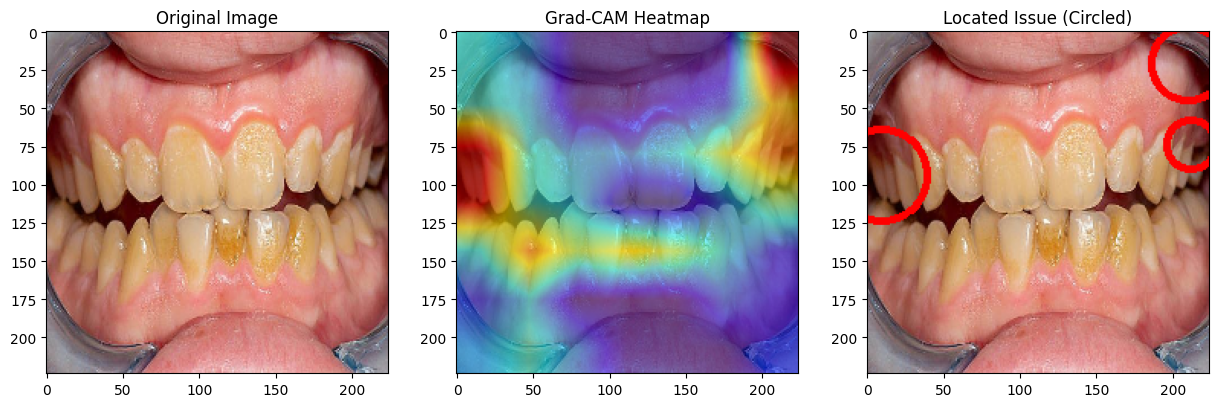

Predicted Condition: Calculus
Confidence: 99.24%


In [ ]:
import cv2
import matplotlib.pyplot as plt
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from PIL import Image
import numpy as np
import os
import torch

# --- FIX: Unfreeze model parameters so Grad-CAM can compute gradients ---
for param in model.parameters():
    param.requires_grad = True
# ------------------------------------------------------------------------

# 1. Setup Grad-CAM (Targeting the last convolutional layer of MobileNet)
target_layers = [model.features[-1]]
cam = GradCAM(model=model, target_layers=target_layers)

# 2. Automatically find a valid test image
test_class = 'Calculus'
class_folder = os.path.join(data_dir, test_class)
available_images = [f for f in os.listdir(class_folder) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
img_path = os.path.join(class_folder, available_images[0])

# 3. Load the image
img = Image.open(img_path).convert('RGB')

# 4. Preprocess the image for the model
input_tensor = data_transforms['val'](img).unsqueeze(0).to(device)

# 5. Generate the Heatmap
grayscale_cam = cam(input_tensor=input_tensor, targets=None)[0, :]

# 6. Overlay heatmap on original image for visualization
rgb_img = cv2.resize(np.array(img), (224, 224))
rgb_img_float = np.float32(rgb_img) / 255
visualization = show_cam_on_image(rgb_img_float, grayscale_cam, use_rgb=True)

# 7. Draw a circle around the most intensely activated region
mask = (grayscale_cam > 0.7).astype(np.uint8) * 255
contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

output_img = rgb_img.copy()
for cnt in contours:
    (x, y), radius = cv2.minEnclosingCircle(cnt)
    if radius > 10:
        cv2.circle(output_img, (int(x), int(y)), int(radius), (255, 0, 0), 3)

# 8. Display the results
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(rgb_img)
ax[0].set_title('Original Image')
ax[1].imshow(visualization)
ax[1].set_title('Grad-CAM Heatmap')
ax[2].imshow(output_img)
ax[2].set_title('Located Issue (Circled)')
plt.show()

# Get the model's text prediction
model.eval()
with torch.no_grad():
    output = model(input_tensor)
    prediction_idx = torch.argmax(output).item()
    confidence = torch.softmax(output, dim=1)[0][prediction_idx].item()
    predicted_class = full_dataset.classes[prediction_idx]

print(f"Predicted Condition: {predicted_class}")
print(f"Confidence: {confidence * 100:.2f}%")

Upload a dental photo from your computer to test:


Saving WhatsApp Image 2026-11-05 at 12.56.42 PM.jpeg to WhatsApp Image 2026-11-05 at 12.56.42 PM.jpeg

Predicted Condition: tooth discoloration
AI Confidence:       99.95%

Result: tooth discoloration detected. Running AI localization...


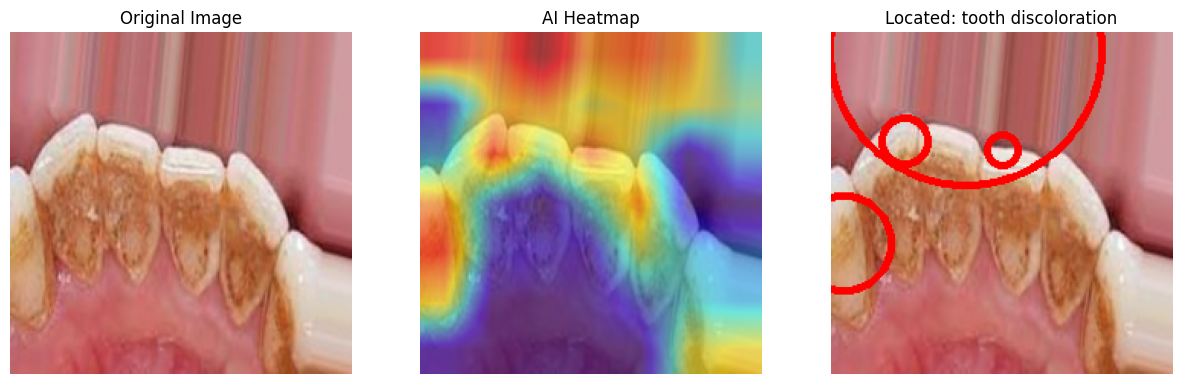

In [ ]:
import cv2
import matplotlib.pyplot as plt
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from PIL import Image
import numpy as np
import torch
from google.colab import files

print("Upload a dental photo from your computer to test:")
uploaded = files.upload() # This will prompt you to choose a file

# Only run if a file was actually uploaded
if len(uploaded) > 0:
    # 1. Get the uploaded image name and load it
    img_path = list(uploaded.keys())[0]
    img = Image.open(img_path).convert('RGB')

    # 2. Preprocess the image for the model
    input_tensor = data_transforms['val'](img).unsqueeze(0).to(device)

    # 3. GET PREDICTION FIRST
    model.eval()
    with torch.no_grad():
        output = model(input_tensor)
        prediction_idx = torch.argmax(output).item()
        confidence = torch.softmax(output, dim=1)[0][prediction_idx].item()
        predicted_class = full_dataset.classes[prediction_idx]

    print(f"\n=====================================")
    print(f"Predicted Condition: {predicted_class}")
    print(f"AI Confidence:       {confidence * 100:.2f}%")
    print(f"=====================================\n")

    # Resize original image for clean display
    rgb_img = cv2.resize(np.array(img), (224, 224))

    # 4. CONDITIONAL DISPLAY (Normal vs. Issue)
    if predicted_class == 'Normal':
        print("Result: No major issues detected. Displaying original image.")
        plt.figure(figsize=(5, 5))
        plt.imshow(rgb_img)
        plt.title(f'Normal (Confidence: {confidence*100:.1f}%)')
        plt.axis('off')
        plt.show()

    else:
        print(f"Result: {predicted_class} detected. Running AI localization...")

        # Unfreeze model parameters so Grad-CAM can compute gradients
        for param in model.parameters():
            param.requires_grad = True

        # Setup and Run Grad-CAM
        target_layers = [model.features[-1]]
        cam = GradCAM(model=model, target_layers=target_layers)
        grayscale_cam = cam(input_tensor=input_tensor, targets=None)[0, :]

        # Overlay heatmap
        rgb_img_float = np.float32(rgb_img) / 255
        visualization = show_cam_on_image(rgb_img_float, grayscale_cam, use_rgb=True)

        # Draw a circle around the issue
        mask = (grayscale_cam > 0.7).astype(np.uint8) * 255
        contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

        output_img = rgb_img.copy()
        for cnt in contours:
            (x, y), radius = cv2.minEnclosingCircle(cnt)
            if radius > 10:
                cv2.circle(output_img, (int(x), int(y)), int(radius), (255, 0, 0), 3)

        # Display the 3-step visualization
        fig, ax = plt.subplots(1, 3, figsize=(15, 5))
        ax[0].imshow(rgb_img)
        ax[0].set_title('Original Image')
        ax[0].axis('off')

        ax[1].imshow(visualization)
        ax[1].set_title('AI Heatmap')
        ax[1].axis('off')

        ax[2].imshow(output_img)
        ax[2].set_title(f'Located: {predicted_class}')
        ax[2].axis('off')

        plt.show()
